# 6BUIS017W CRM & CM with Business Intelligence — Individual Coursework
**Student Name:** Mohamed Dilshad | **UOW ID:** w2121524 | **IIT No:** 20241148  
**Lecturer:** Mr. Fouzul Hassan | **Study Period:** 2021-01-01 to 2025-01-01 (End Date Exclusive)  
**Benchmark:** S&P 500 Index (`^GSPC`) | **Repository:** https://github.com/mhddilshadgit/cwk1-sp500-rfm-segmentation

In [1]:
# Environment setup (Colab & local compatible)
import sys, os, io, json, time
from pathlib import Path
from datetime import datetime

if "google.colab" in sys.modules:
    !pip install -q yfinance pandas numpy scipy scikit-learn matplotlib seaborn lxml requests pyarrow

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.stats import pearsonr, spearmanr, chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Plot styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Study parameters
START_DATE = "2021-01-01"
END_DATE = "2025-01-01"
BENCHMARK_TICKER = "^GSPC"
ROLLING_BASELINE_DAYS = 20
UNUSUAL_VOLUME_MULTIPLIER = 2.0
RFM_WINDOW_SESSIONS = 60
RANDOM_STATE = 42
K_MEANS_N_INIT = 20
K_RANGE = list(range(2, 9))

# Local cache directories (used if available; otherwise live download runs automatically)
DATA_CACHE_DIR = Path("data/raw")
DATA_CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIG_EXPORT_DIR = Path("outputs/figures")
FIG_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment ready | Study Window: {START_DATE} to {END_DATE} (exclusive) | Benchmark: {BENCHMARK_TICKER}")

Environment ready | Study Window: 2021-01-01 to 2025-01-01 (exclusive) | Benchmark: ^GSPC


# Task 1 Data Preparation and Feature Engineering

## Task 1.1 Ticker selection and data acquisition
Extract the current S&P 500 constituent list from Wikipedia using `pandas`, record the retrieval timestamp, normalize ticker punctuation (`.` to `-`) for Yahoo Finance compatibility, and download daily OHLC, unadjusted `Close`, dividend/split-adjusted `Adj Close`, and `Volume` alongside `^GSPC` via `yfinance` (`auto_adjust=False`) for `2021-01-01` to `2025-01-01` (exclusive).

In [2]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
USER_AGENT = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) 6BUIS017W-CWK1/1.0"

constituents_cache = DATA_CACHE_DIR / "sp500_constituents.csv"
prices_cache = DATA_CACHE_DIR / "sp500_market_data.parquet"
bench_cache = DATA_CACHE_DIR / "benchmark_gspc.parquet"
manifest_cache = DATA_CACHE_DIR / "acquisition_manifest.json"

def fetch_sp500_constituents(cache_path=constituents_cache, force_refresh=False):
    if cache_path.exists() and not force_refresh:
        return pd.read_csv(cache_path)
    resp = requests.get(WIKI_URL, headers={"User-Agent": USER_AGENT}, timeout=15)
    resp.raise_for_status()
    df = pd.read_html(io.StringIO(resp.text))[0].copy()
    rename_map = {
        "Symbol": "ticker",
        "Security": "company_name",
        "GICS Sector": "sector",
        "GICS Sub-Industry": "sub_industry",
        "Headquarters Location": "headquarters",
        "Date added": "date_added",
        "CIK": "cik",
        "Founded": "founded",
    }
    df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})
    df["raw_symbol"] = df["ticker"]
    df["ticker"] = df["ticker"].str.replace(".", "-", regex=False)
    df["retrieval_date"] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    df.to_csv(cache_path, index=False)
    return df

def download_market_data(tickers, start_date=START_DATE, end_date=END_DATE, batch_size=50, force_refresh=False):
    if prices_cache.exists() and bench_cache.exists() and manifest_cache.exists() and not force_refresh:
        stock_data = pd.read_parquet(prices_cache)
        bench_data = pd.read_parquet(bench_cache)
        with open(manifest_cache, "r", encoding="utf-8") as f:
            manifest = json.load(f)
        return stock_data, bench_data, manifest

    bench_data = yf.download(BENCHMARK_TICKER, start=start_date, end=end_date, auto_adjust=False, progress=False)
    if isinstance(bench_data.columns, pd.MultiIndex):
        bench_data.columns = [c[0] for c in bench_data.columns]
    bench_data.index = pd.to_datetime(bench_data.index).tz_localize(None)
    bench_data.to_parquet(bench_cache)

    all_frames, failed_tickers = [], []
    for i in range(0, len(tickers), batch_size):
        batch = tickers[i : i + batch_size]
        batch_df = yf.download(batch, start=start_date, end=end_date, auto_adjust=False, group_by="ticker", threads=True, progress=False)
        if len(batch) == 1:
            t = batch[0]
            if isinstance(batch_df.columns, pd.MultiIndex):
                batch_df.columns = [c[0] for c in batch_df.columns]
            batch_df["ticker"] = t
            all_frames.append(batch_df.reset_index())
        else:
            for t in batch:
                try:
                    if t in batch_df.columns.levels[0]:
                        t_df = batch_df[t].copy()
                    elif t in batch_df.columns.levels[1]:
                        t_df = batch_df.xs(t, axis=1, level=1).copy()
                    else:
                        failed_tickers.append(t)
                        continue
                    t_df = t_df.dropna(how="all")
                    if not t_df.empty:
                        t_df["ticker"] = t
                        all_frames.append(t_df.reset_index())
                    else:
                        failed_tickers.append(t)
                except Exception:
                    failed_tickers.append(t)
        time.sleep(0.3)

    market_df = pd.concat(all_frames, ignore_index=True)
    date_col = "Date" if "Date" in market_df.columns else "index"
    market_df["Date"] = pd.to_datetime(market_df[date_col]).dt.tz_localize(None)
    if date_col != "Date":
        market_df = market_df.drop(columns=[date_col])
    market_df.to_parquet(prices_cache, index=False)

    manifest = {
        "study_window_start": start_date,
        "study_window_end_exclusive": end_date,
        "retrieval_timestamp": datetime.now().isoformat(),
        "total_tickers_requested": len(tickers),
        "total_tickers_retrieved": int(market_df["ticker"].nunique()),
        "failed_tickers": failed_tickers,
        "benchmark_ticker": BENCHMARK_TICKER,
        "benchmark_trading_days": len(bench_data),
        "auto_adjust": False,
    }
    with open(manifest_cache, "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2)
    return market_df, bench_data, manifest

constituents_df = fetch_sp500_constituents()
tickers = constituents_df["ticker"].tolist()
market_df, bench_df, manifest = download_market_data(tickers=tickers)

print(f"Retrieval Timestamp : {manifest['retrieval_timestamp']}")
print(f"Constituents Listed : {manifest['total_tickers_requested']}")
print(f"Tickers Acquired    : {manifest['total_tickers_retrieved']} | Failed Downloads: {manifest['failed_tickers']}")
print(f"Benchmark (^GSPC)   : {manifest['benchmark_trading_days']} trading sessions ({START_DATE} to {END_DATE})")
display(constituents_df[["ticker", "company_name", "sector", "sub_industry", "retrieval_date"]].head(8))

Retrieval Timestamp : 2026-11-23T01:56:11.203253
Constituents Listed : 503
Tickers Acquired    : 498 | Failed Downloads: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Benchmark (^GSPC)   : 1005 trading sessions (2021-01-01 to 2025-01-01)


,ticker,company_name,sector,sub_industry,retrieval_date
0,MMM,3M,Industrials,Industrial Conglomerates,2026-11-23 01:55:22
1,AOS,A. O. Smith,Industrials,Building Products,2026-11-23 01:55:22
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,2026-11-23 01:55:22
3,ABBV,AbbVie,Health Care,Biotechnology,2026-11-23 01:55:22
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,2026-11-23 01:55:22
5,ADBE,Adobe Inc.,Information Technology,Application Software,2026-11-23 01:55:22
6,AMD,Advanced Micro Devices,Information Technology,Semiconductors,2026-11-23 01:55:22
7,AES,AES Corporation,Utilities,Independent Power Producers & Energy Traders,2026-11-23 01:55:22


## Task 1.2 Data validation and alignment
Check duplicate timestamps, missing or non-positive prices, persistent zero-volume anomalies, unequal historical coverage (< 95% of benchmark sessions), and final 60-session completeness. Exclusions are logged transparently without silent forward-filling.

In [3]:
def validate_market_data(market_df, benchmark_df, constituents_df, min_trading_days_ratio=0.95):
    df = market_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    bench = benchmark_df.copy()
    bench.index = pd.to_datetime(bench.index)

    benchmark_sessions = len(bench)
    min_required_days = int(benchmark_sessions * min_trading_days_ratio)

    initial_rows = len(df)
    df = df.drop_duplicates(subset=["ticker", "Date"]).copy()
    duplicates_removed = initial_rows - len(df)

    last_60_bench_dates = set(bench.index.sort_values()[-RFM_WINDOW_SESSIONS:])
    const_meta = constituents_df.set_index("ticker").to_dict(orient="index")

    excluded_records, valid_tickers = [], []
    for ticker, group in df.groupby("ticker"):
        meta = const_meta.get(ticker, {})
        comp_name = meta.get("company_name", ticker)
        sector = meta.get("sector", "Unknown")
        days_present = len(group)
        missing_days = benchmark_sessions - days_present

        if ((group["Close"] <= 0) | group["Close"].isna()).any() or ((group["Adj Close"] <= 0) | group["Adj Close"].isna()).any():
            reason = "Non-positive or missing price values detected"
        elif days_present < min_required_days:
            reason = f"Insufficient historical coverage ({days_present}/{benchmark_sessions} days, {group['Date'].min():%Y-%m-%d} to {group['Date'].max():%Y-%m-%d})"
        elif len(last_60_bench_dates - set(group["Date"])) > 2:
            reason = f"Incomplete coverage in final 60 RFM trading sessions"
        elif (group["Volume"] <= 0).sum() > (0.05 * days_present):
            reason = f"Persistent zero or negative volume anomalies ({int((group['Volume'] <= 0).sum())} days)"
        else:
            valid_tickers.append(ticker)
            continue

        excluded_records.append({
            "ticker": ticker,
            "company_name": comp_name,
            "sector": sector,
            "trading_days_present": days_present,
            "missing_days": missing_days,
            "exclusion_reason": reason,
        })

    valid_market_df = df[df["ticker"].isin(valid_tickers)].sort_values(["ticker", "Date"]).reset_index(drop=True)
    exclusion_log_df = pd.DataFrame(excluded_records)

    summary = {
        "benchmark_trading_days": benchmark_sessions,
        "raw_tickers_inspected": int(df["ticker"].nunique()),
        "retained_valid_tickers": len(valid_tickers),
        "excluded_tickers_count": len(exclusion_log_df),
        "duplicate_rows_removed": duplicates_removed,
        "observation_date": bench.index.max().strftime("%Y-%m-%d"),
        "retained_market_rows": len(valid_market_df),
    }
    return valid_market_df, exclusion_log_df, summary

valid_market_df, exclusion_log_df, val_summary = validate_market_data(market_df, bench_df, constituents_df)
print(f"Validation Summary: {val_summary}")
display(exclusion_log_df)

Validation Summary: {'benchmark_trading_days': 1005, 'raw_tickers_inspected': 498, 'retained_valid_tickers': 488, 'excluded_tickers_count': 10, 'duplicate_rows_removed': 0, 'observation_date': '2024-12-31', 'retained_market_rows': 490414}


,ticker,company_name,sector,trading_days_present,missing_days,exclusion_reason
0,APP,AppLovin,Communication Services,935,70,Insufficient historical coverage (935/1005 day...
1,CEG,Constellation Energy,Utilities,742,263,Insufficient historical coverage (742/1005 day...
2,COIN,Coinbase,Financials,936,69,Insufficient historical coverage (936/1005 day...
3,GEHC,GE HealthCare,Health Care,513,492,Insufficient historical coverage (513/1005 day...
4,GEV,GE Vernova,Industrials,193,812,Insufficient historical coverage (193/1005 day...
5,HOOD,Robinhood Markets,Financials,862,143,Insufficient historical coverage (862/1005 day...
6,RDDT,Reddit,Communication Services,197,808,Insufficient historical coverage (197/1005 day...
7,SOLV,Solventum,Health Care,194,811,Insufficient historical coverage (194/1005 day...
8,SW,Smurfit Westrock,Materials,1005,0,Persistent zero or negative volume anomalies (...
9,VLTO,Veralto,Industrials,313,692,Insufficient historical coverage (313/1005 day...


## Task 1.3 Weekly return and weekly beta
### Task 1.3.1 Mean weekly return
Resample daily `Adj Close` to Friday-ending calendar weeks (`W-FRI`) using the final available trading session in each week. Enforce consecutive 7-day spacing so missing intermediate weeks never become multi-week returns, while retaining holiday-shortened weeks.

In [4]:
def compute_weekly_prices(daily_df, price_col="Adj Close"):
    df = daily_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").set_index("Date")
    return df[price_col].resample("W-FRI").last().dropna()

def calculate_weekly_returns(weekly_prices):
    wp = weekly_prices.sort_index()
    returns = wp.pct_change()
    date_diffs = wp.index.to_series().diff().dt.days
    returns[date_diffs > 7] = np.nan
    return returns.dropna()

bench_clean = bench_df.reset_index()
date_col = "Date" if "Date" in bench_clean.columns else bench_clean.columns[0]
bench_clean["Date"] = pd.to_datetime(bench_clean[date_col])
bench_price_col = "Adj Close" if "Adj Close" in bench_clean.columns else "Close"
bench_weekly_returns = calculate_weekly_returns(compute_weekly_prices(bench_clean, price_col=bench_price_col))
bench_weekly_returns.name = "BENCHMARK"

stock_returns_dict = {
    ticker: calculate_weekly_returns(compute_weekly_prices(sub_df, price_col="Adj Close"))
    for ticker, sub_df in valid_market_df.groupby("ticker")
}
aligned_returns = pd.DataFrame(stock_returns_dict).join(bench_weekly_returns, how="inner")
print(f"Aligned weekly return observations for ^GSPC: {len(bench_weekly_returns)} weeks ({aligned_returns.index.min():%Y-%m-%d} to {aligned_returns.index.max():%Y-%m-%d})")

Aligned weekly return observations for ^GSPC: 208 weeks (2021-01-15 to 2025-01-03)


### Task 1.3.2 Weekly beta
Compute sample covariance between each share's weekly returns and matched `^GSPC` weekly returns divided by benchmark weekly return variance (`ddof=1`).

In [5]:
bench_ret_series = aligned_returns["BENCHMARK"]
rb_rows = []
for ticker in valid_market_df["ticker"].unique():
    stock_series = aligned_returns[ticker].dropna()
    matched_bench = bench_ret_series.loc[stock_series.index]
    n_obs = len(stock_series)
    if n_obs < 30:
        continue
    mean_ret = stock_series.mean()
    cov_sb = np.cov(stock_series, matched_bench, ddof=1)[0, 1]
    bench_var = np.var(matched_bench, ddof=1)
    beta = cov_sb / bench_var if bench_var > 0 else np.nan
    rb_rows.append({
        "ticker": ticker,
        "mean_weekly_return": mean_ret,
        "weekly_beta": beta,
        "weekly_obs_count": n_obs,
        "annualized_return_approx": mean_ret * 52,
    })

returns_beta_df = pd.DataFrame(rb_rows).set_index("ticker")
display(returns_beta_df.describe().T.round(6))

,count,mean,std,min,25%,50%,75%,max
mean_weekly_return,488.0,0.002808,0.002628,-0.004423,0.001138,0.002575,0.004184,0.017462
weekly_beta,488.0,0.972440,0.406392,0.056026,0.667341,0.944596,1.176213,3.778556
weekly_obs_count,488.0,207.989754,0.226339,203.000000,208.000000,208.000000,208.000000,208.000000
annualized_return_approx,488.0,0.146038,0.136648,-0.230018,0.059179,0.133912,0.217582,0.908000


## Task 1.4 Adapted RFM Calculations
Anchor the observation date at the final completed trading day (`2024-12-31`). Define an unusual high-volume day as `Volume > 2.0 * mean(Volume_{t-20..t-1})`, strictly excluding day `t` via `.shift(1)`.

In [6]:
def compute_unusual_volume_events(stock_df, baseline_window=ROLLING_BASELINE_DAYS, multiplier=UNUSUAL_VOLUME_MULTIPLIER):
    df = stock_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    df["prior_20_mean_vol"] = df["Volume"].shift(1).rolling(window=baseline_window, min_periods=baseline_window).mean()
    df["volume_threshold"] = multiplier * df["prior_20_mean_vol"]
    df["is_unusual_volume"] = (df["Volume"] > df["volume_threshold"]) & df["prior_20_mean_vol"].notna()
    df["daily_traded_value_usd"] = df["Close"] * df["Volume"]
    return df

obs_date = pd.to_datetime(valid_market_df["Date"]).max()
print(f"Observation Date: {obs_date.strftime('%Y-%m-%d')}")

Observation Date: 2024-12-31


### Task 1.4.1 Recency, Task 1.4.2 Frequency, and Task 1.4.3 Monetary
- **Recency (R):** Calendar days between latest qualifying volume spike and observation date (missing `NaN` if no spike occurred).
- **Frequency (F):** Count of qualifying high-volume days in the final 60 trading sessions.
- **Monetary (M):** Sum of `Close * Volume` (USD) over the final 60 trading sessions, plus an `Adj Close / Close` ratio check for corporate splits in that window.

In [7]:
def calculate_rfm_for_ticker(ticker_df, observation_date, rfm_window=RFM_WINDOW_SESSIONS):
    df_events = compute_unusual_volume_events(ticker_df)
    df_upto = df_events[df_events["Date"] <= observation_date].copy()
    last_60 = df_upto.iloc[-rfm_window:].copy()

    freq = int(last_60["is_unusual_volume"].sum())
    monetary = float(last_60["daily_traded_value_usd"].sum())

    event_days = df_upto[df_upto["is_unusual_volume"]]
    if event_days.empty:
        recency = np.nan
        latest_event_str = None
    else:
        latest_event = event_days["Date"].max()
        latest_event_str = latest_event.strftime("%Y-%m-%d")
        diff_days = (observation_date - latest_event).days
        recency = 1.0 if diff_days == 0 else float(diff_days)

    # Check if Adj Close / Close ratio changed inside the 60-session Monetary window
    ratio = last_60["Adj Close"] / last_60["Close"]
    ratio_stable = (ratio.max() / ratio.min() - 1.0) < 0.01

    return {
        "R": recency,
        "F": freq,
        "M": monetary,
        "latest_event_date": latest_event_str,
        "rfm_sessions": len(last_60),
        "window_split_free": ratio_stable,
    }

rfm_rows = []
for ticker, sub_df in valid_market_df.groupby("ticker"):
    m = calculate_rfm_for_ticker(sub_df, obs_date)
    m["ticker"] = ticker
    rfm_rows.append(m)

rfm_df = pd.DataFrame(rfm_rows).set_index("ticker")
rfm_df["log1p_M"] = np.log1p(rfm_df["M"])
print(f"Missing Recency (no spike) count: {int(rfm_df['R'].isna().sum())}")
display(rfm_df[["R", "F", "M", "log1p_M"]].describe().T)

Missing Recency (no spike) count: 0


,count,mean,std,min,25%,50%,75%,max
R,488.0,2.038934e+01,2.130284e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F,488.0,2.987705e+00,1.328820e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,488.0,3.930869e+10,1.288821e+11,1.297483e+09,1.023194e+10,1.668382e+10,3.210048e+10,1.847697e+12
log1p_M,488.0,2.368135e+01,9.403836e-01,2.098369e+01,2.304878e+01,2.353770e+01,2.419213e+01,2.824496e+01


## Task 1.5 Metric interpretation and supporting evidence
Present a worked RFM example for Apple Inc. (`AAPL`), verify sufficient history across the 20-session baseline and 60-session windows, and summarize all five features on the common valid share universe (`N = 488`).

In [8]:
# Worked RFM Example: AAPL
aapl_events = compute_unusual_volume_events(valid_market_df[valid_market_df["ticker"] == "AAPL"])
aapl_60 = aapl_events[aapl_events["Date"] <= obs_date].iloc[-RFM_WINDOW_SESSIONS:].copy()
print(f"AAPL Summary -> R = {rfm_df.loc['AAPL', 'R']:.0f} days (latest spike: {rfm_df.loc['AAPL', 'latest_event_date']}), "
      f"F = {rfm_df.loc['AAPL', 'F']} days, M = ${rfm_df.loc['AAPL', 'M']/1e9:.2f}B, log1p(M) = {rfm_df.loc['AAPL', 'log1p_M']:.4f}")
display(aapl_60[aapl_60["is_unusual_volume"]][["Date", "Close", "Volume", "prior_20_mean_vol", "volume_threshold", "daily_traded_value_usd"]])

# Common valid share set across Risk/Return and RFM
valid_a = returns_beta_df[["mean_weekly_return", "weekly_beta"]].dropna()
valid_b = rfm_df[["R", "F", "M", "log1p_M"]].dropna()
common_tickers = valid_a.index.intersection(valid_b.index)
print(f"Common Valid Share Universe: N = {len(common_tickers)}")

combined_raw = valid_a.loc[common_tickers].join(valid_b.loc[common_tickers, ["R", "F", "M", "log1p_M"]])
summary_15 = combined_raw.describe().T
summary_15["skewness"] = combined_raw.skew()
summary_15["kurtosis"] = combined_raw.kurtosis()
display(summary_15.round(4))

AAPL Summary -> R = 11 days (latest spike: 2024-12-20), F = 2 days, M = $623.30B, log1p(M) = 27.1583


,Date,Close,Volume,prior_20_mean_vol,volume_threshold,daily_traded_value_usd
980,2024-11-25,232.869995,90152800.0,43820740.0,87641480.0,2.099388e+10
998,2024-12-20,254.490005,147495300.0,45004605.0,90009210.0,3.753608e+10


Common Valid Share Universe: N = 488


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
mean_weekly_return,488.0,2.800000e-03,2.600000e-03,-4.400000e-03,1.100000e-03,2.600000e-03,4.200000e-03,1.750000e-02,0.8443,2.9142
weekly_beta,488.0,9.724000e-01,4.064000e-01,5.600000e-02,6.673000e-01,9.446000e-01,1.176200e+00,3.778600e+00,1.1127,4.5172
R,488.0,2.038930e+01,2.130280e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02,3.6534,21.0949
F,488.0,2.987700e+00,1.328800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00,0.4286,0.5546
M,488.0,3.930869e+10,1.288821e+11,1.297483e+09,1.023194e+10,1.668382e+10,3.210048e+10,1.847697e+12,11.7075,156.1506
log1p_M,488.0,2.368140e+01,9.404000e-01,2.098370e+01,2.304880e+01,2.353770e+01,2.419210e+01,2.824500e+01,1.0833,2.7153


# Task 2 Stock Segmentation and Sensitivity Analysis

## Task 2.1 Feature preparation
Construct two separate feature matrices on the common 488 shares:
- **Matrix A (Risk & Return):** `[mean_weekly_return, weekly_beta]`
- **Matrix B (Trading Activity):** `[R, F, log1p_M]`

Inspect skewness and IQR outliers, apply `log1p(M)` to compress heavy right-tail dollar turnover skewness, and apply independent `StandardScaler` standardization to each matrix.

mean_weekly_return   | Skew =   0.84 | IQR Outliers =  3.07%
weekly_beta          | Skew =   1.11 | IQR Outliers =  2.05%
R                    | Skew =   3.65 | IQR Outliers = 23.16%
F                    | Skew =   0.43 | IQR Outliers =  0.41%
M                    | Skew =  11.71 | IQR Outliers =  9.22%
log1p_M              | Skew =   1.08 | IQR Outliers =  2.66%


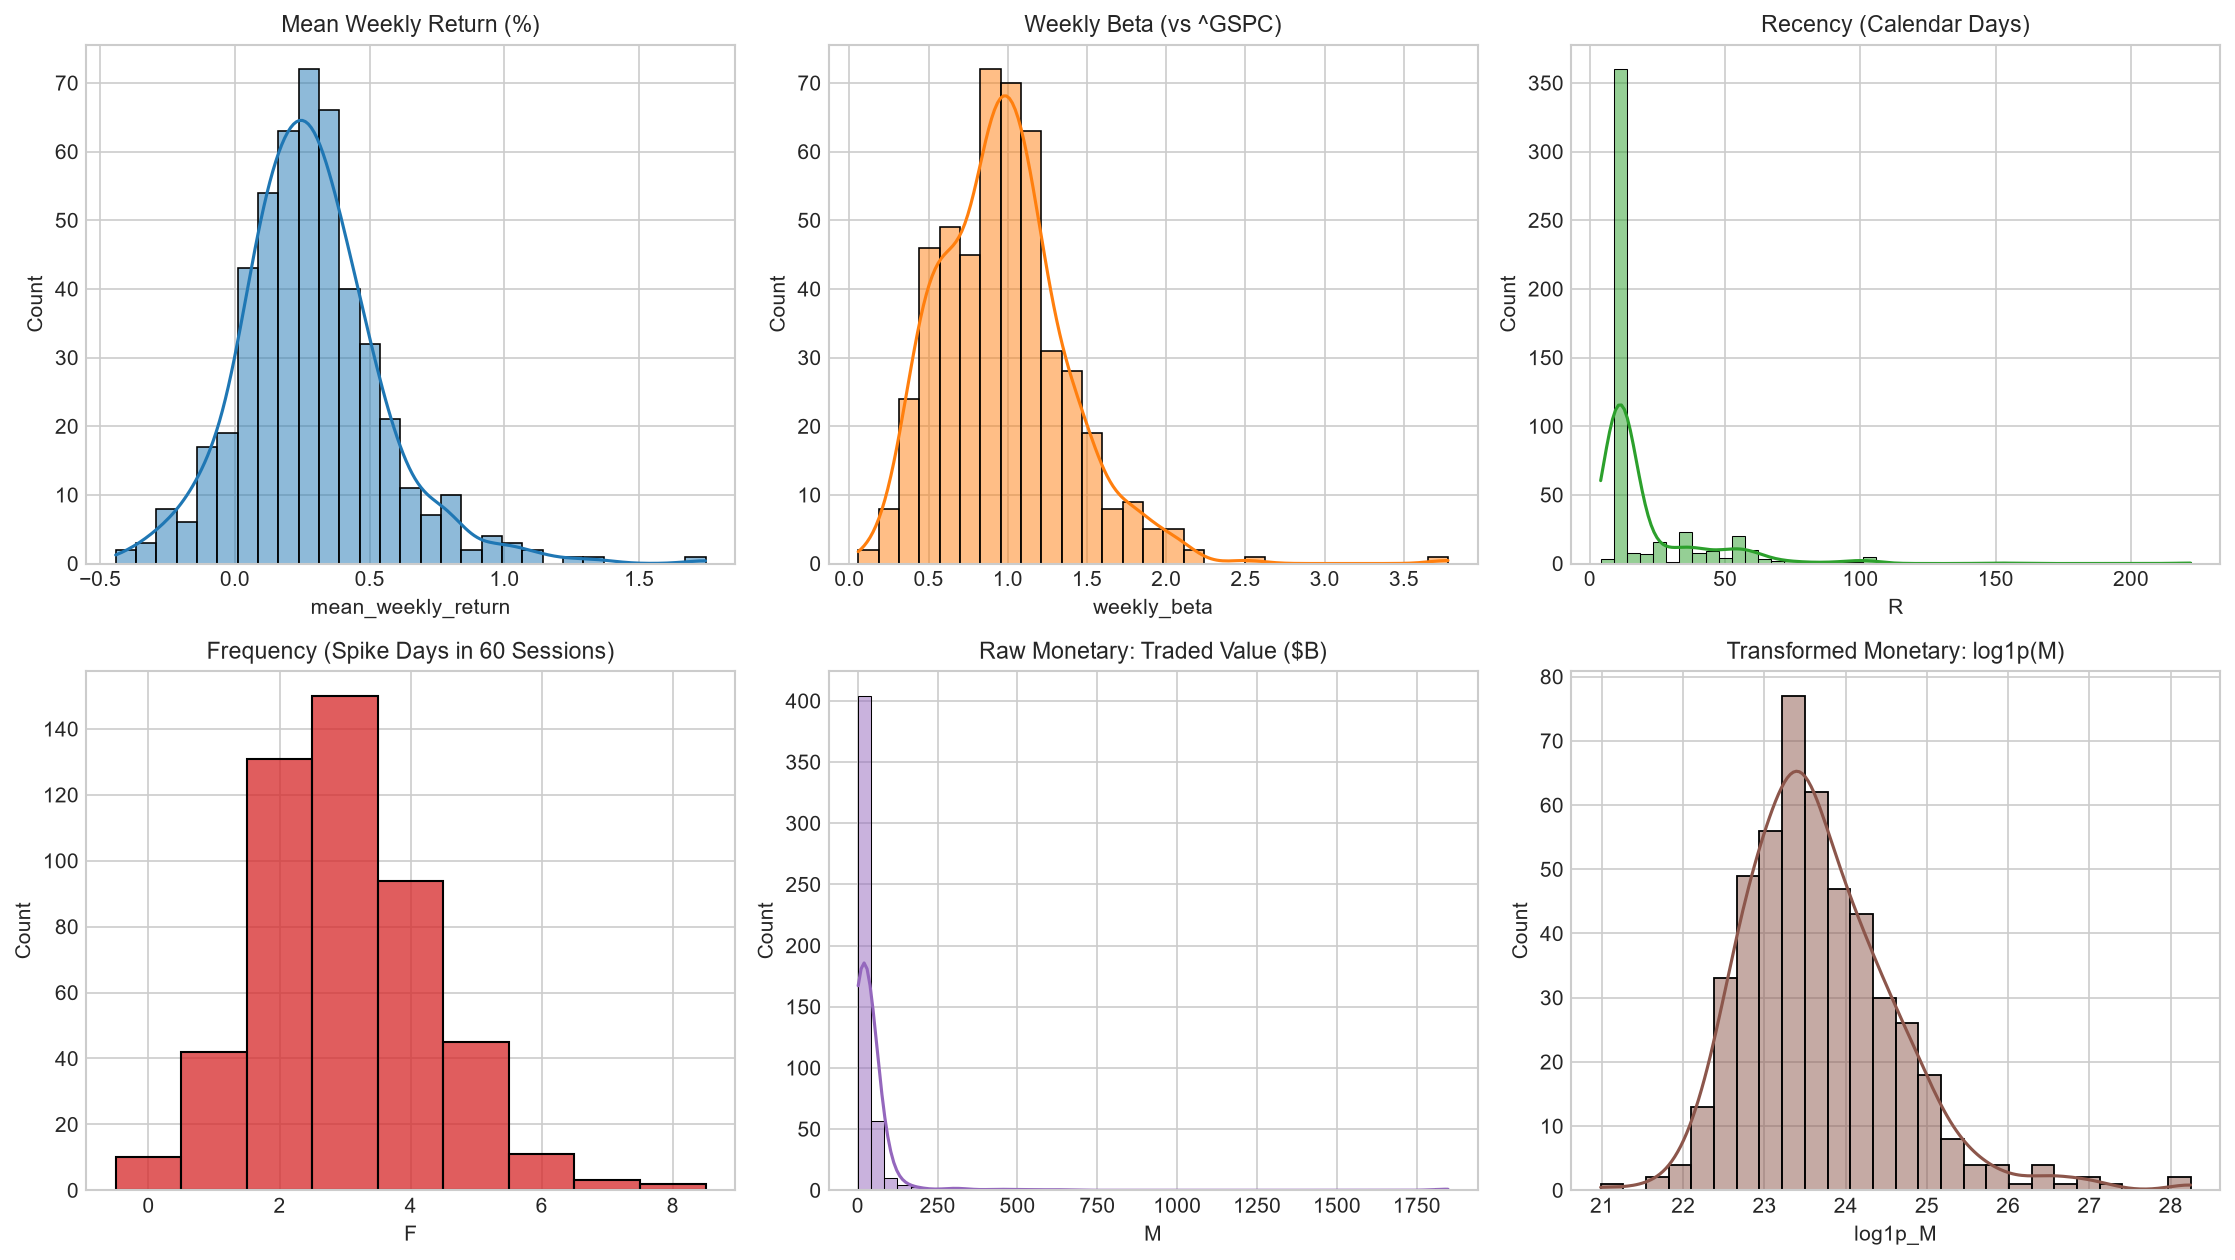

In [9]:
matrix_a_raw = valid_a.loc[common_tickers, ["mean_weekly_return", "weekly_beta"]].copy()
matrix_b_raw = valid_b.loc[common_tickers, ["R", "F", "log1p_M"]].copy()
original_m = valid_b.loc[common_tickers, "M"]

# IQR outlier audit
for col, s in [("mean_weekly_return", matrix_a_raw["mean_weekly_return"]),
               ("weekly_beta", matrix_a_raw["weekly_beta"]),
               ("R", matrix_b_raw["R"]),
               ("F", matrix_b_raw["F"]),
               ("M", original_m),
               ("log1p_M", matrix_b_raw["log1p_M"])]:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    out_pct = (((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()) * 100
    print(f"{col:20s} | Skew = {s.skew():6.2f} | IQR Outliers = {out_pct:5.2f}%")

scaler_a = StandardScaler()
matrix_a_scaled = pd.DataFrame(scaler_a.fit_transform(matrix_a_raw), index=common_tickers, columns=["scaled_return", "scaled_beta"])

scaler_b = StandardScaler()
matrix_b_scaled = pd.DataFrame(scaler_b.fit_transform(matrix_b_raw), index=common_tickers, columns=["scaled_R", "scaled_F", "scaled_log1p_M"])

# Plot feature distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
sns.histplot(matrix_a_raw["mean_weekly_return"] * 100, kde=True, ax=axes[0, 0], color="#1f77b4")
axes[0, 0].set_title("Mean Weekly Return (%)")
sns.histplot(matrix_a_raw["weekly_beta"], kde=True, ax=axes[0, 1], color="#ff7f0e")
axes[0, 1].set_title("Weekly Beta (vs ^GSPC)")
sns.histplot(matrix_b_raw["R"], kde=True, ax=axes[0, 2], color="#2ca02c")
axes[0, 2].set_title("Recency (Calendar Days)")
sns.histplot(matrix_b_raw["F"], kde=False, discrete=True, ax=axes[1, 0], color="#d62728")
axes[1, 0].set_title("Frequency (Spike Days in 60 Sessions)")
sns.histplot(original_m / 1e9, kde=True, ax=axes[1, 1], color="#9467bd")
axes[1, 1].set_title("Raw Monetary: Traded Value ($B)")
sns.histplot(matrix_b_raw["log1p_M"], kde=True, ax=axes[1, 2], color="#8c564b")
axes[1, 2].set_title("Transformed Monetary: log1p(M)")
plt.tight_layout()
plt.savefig(FIG_EXPORT_DIR / "fig_2_1_feature_distributions.png")
plt.show()

## Task 2.2 Agglomerative clustering
Fit Ward linkage with Euclidean distance independently on standardized Matrix A and Matrix B, generate one truncated dendrogram per matrix, and compare candidate cluster counts `k = 2..8`.

,k,matrix_a_silhouette,matrix_a_min_size,matrix_a_max_size,matrix_b_silhouette,matrix_b_min_size,matrix_b_max_size
0,2,0.2705,166,322,0.3693,86,402
1,3,0.3040,100,222,0.2597,86,222
2,4,0.2849,66,166,0.2502,86,180
3,5,0.2981,5,166,0.2689,10,180
4,6,0.3010,5,156,0.2903,10,162
5,7,0.3127,5,156,0.2799,10,136
6,8,0.3215,5,156,0.2811,1,136


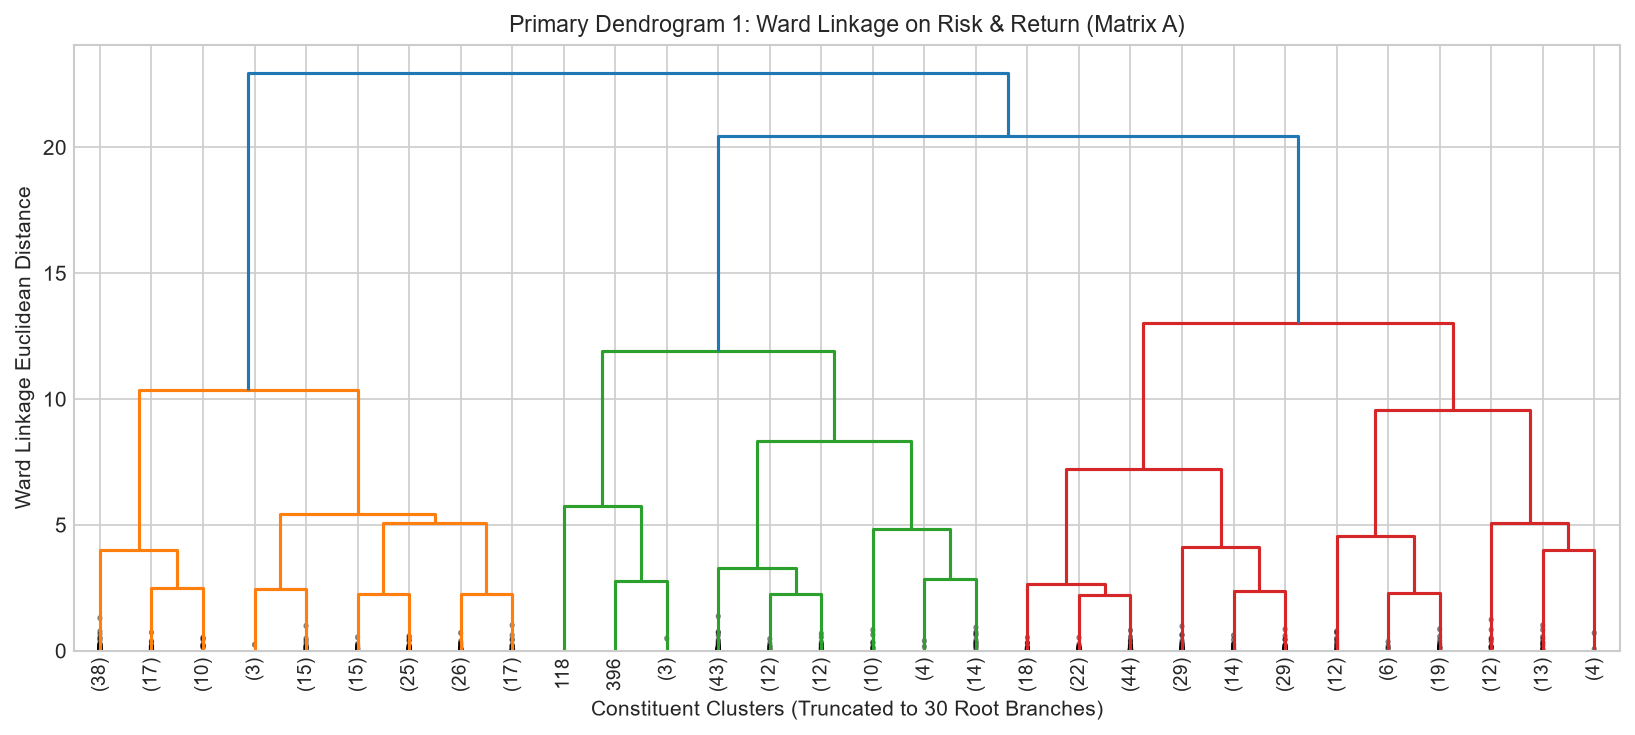

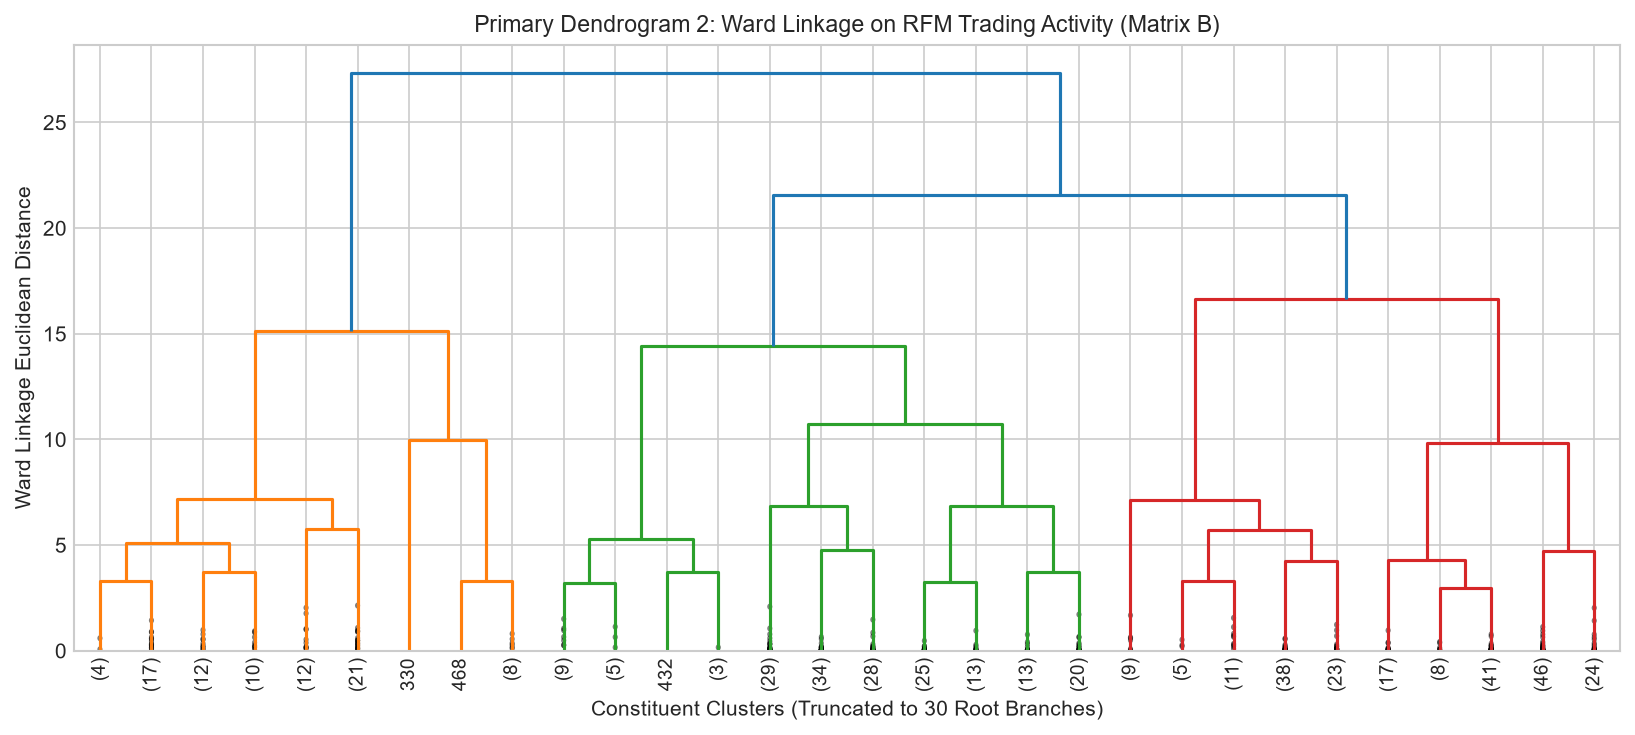

In [10]:
linkage_a = linkage(matrix_a_scaled.values, method="ward", metric="euclidean")
linkage_b = linkage(matrix_b_scaled.values, method="ward", metric="euclidean")

ward_records = []
for k in K_RANGE:
    la = fcluster(linkage_a, t=k, criterion="maxclust")
    lb = fcluster(linkage_b, t=k, criterion="maxclust")
    sa = pd.Series(la).value_counts()
    sb = pd.Series(lb).value_counts()
    ward_records.append({
        "k": k,
        "matrix_a_silhouette": silhouette_score(matrix_a_scaled.values, la),
        "matrix_a_min_size": int(sa.min()),
        "matrix_a_max_size": int(sa.max()),
        "matrix_b_silhouette": silhouette_score(matrix_b_scaled.values, lb),
        "matrix_b_min_size": int(sb.min()),
        "matrix_b_max_size": int(sb.max()),
    })
ward_diag_df = pd.DataFrame(ward_records)
display(ward_diag_df.round(4))

for link_mat, title, fname in [
    (linkage_a, "Primary Dendrogram 1: Ward Linkage on Risk & Return (Matrix A)", "fig_2_2_dendrogram_risk_return.png"),
    (linkage_b, "Primary Dendrogram 2: Ward Linkage on RFM Trading Activity (Matrix B)", "fig_2_2_dendrogram_rfm.png"),
]:
    fig, ax = plt.subplots(figsize=(11, 5))
    dendrogram(link_mat, truncate_mode="lastp", p=30, leaf_rotation=90.0, leaf_font_size=9.0, show_contracted=True, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Constituent Clusters (Truncated to 30 Root Branches)")
    ax.set_ylabel("Ward Linkage Euclidean Distance")
    plt.tight_layout()
    plt.savefig(FIG_EXPORT_DIR / fname)
    plt.show()

## Task 2.3 K-Means clustering
Execute K-Means across `k = 2..8` with `random_state=42` and `n_init=20` on both standardized matrices, comparing inertia elbow curves, silhouette scores, and cluster sizes.

,k,matrix_a_inertia,matrix_a_silhouette,matrix_a_min_size,matrix_a_max_size,matrix_b_inertia,matrix_b_silhouette,matrix_b_min_size,matrix_b_max_size
0,2,627.1687,0.3848,144,344,1071.6028,0.4238,68,420
1,3,465.2784,0.3270,121,203,800.9183,0.3249,63,274
2,4,374.4149,0.3266,41,163,612.5614,0.3413,61,214
3,5,312.1325,0.3396,28,169,517.1663,0.3579,11,200
4,6,266.6236,0.3290,23,134,440.0147,0.3455,11,142
5,7,229.6815,0.3558,16,145,390.4537,0.3460,1,142
6,8,196.5410,0.3539,5,138,343.7602,0.3424,1,151


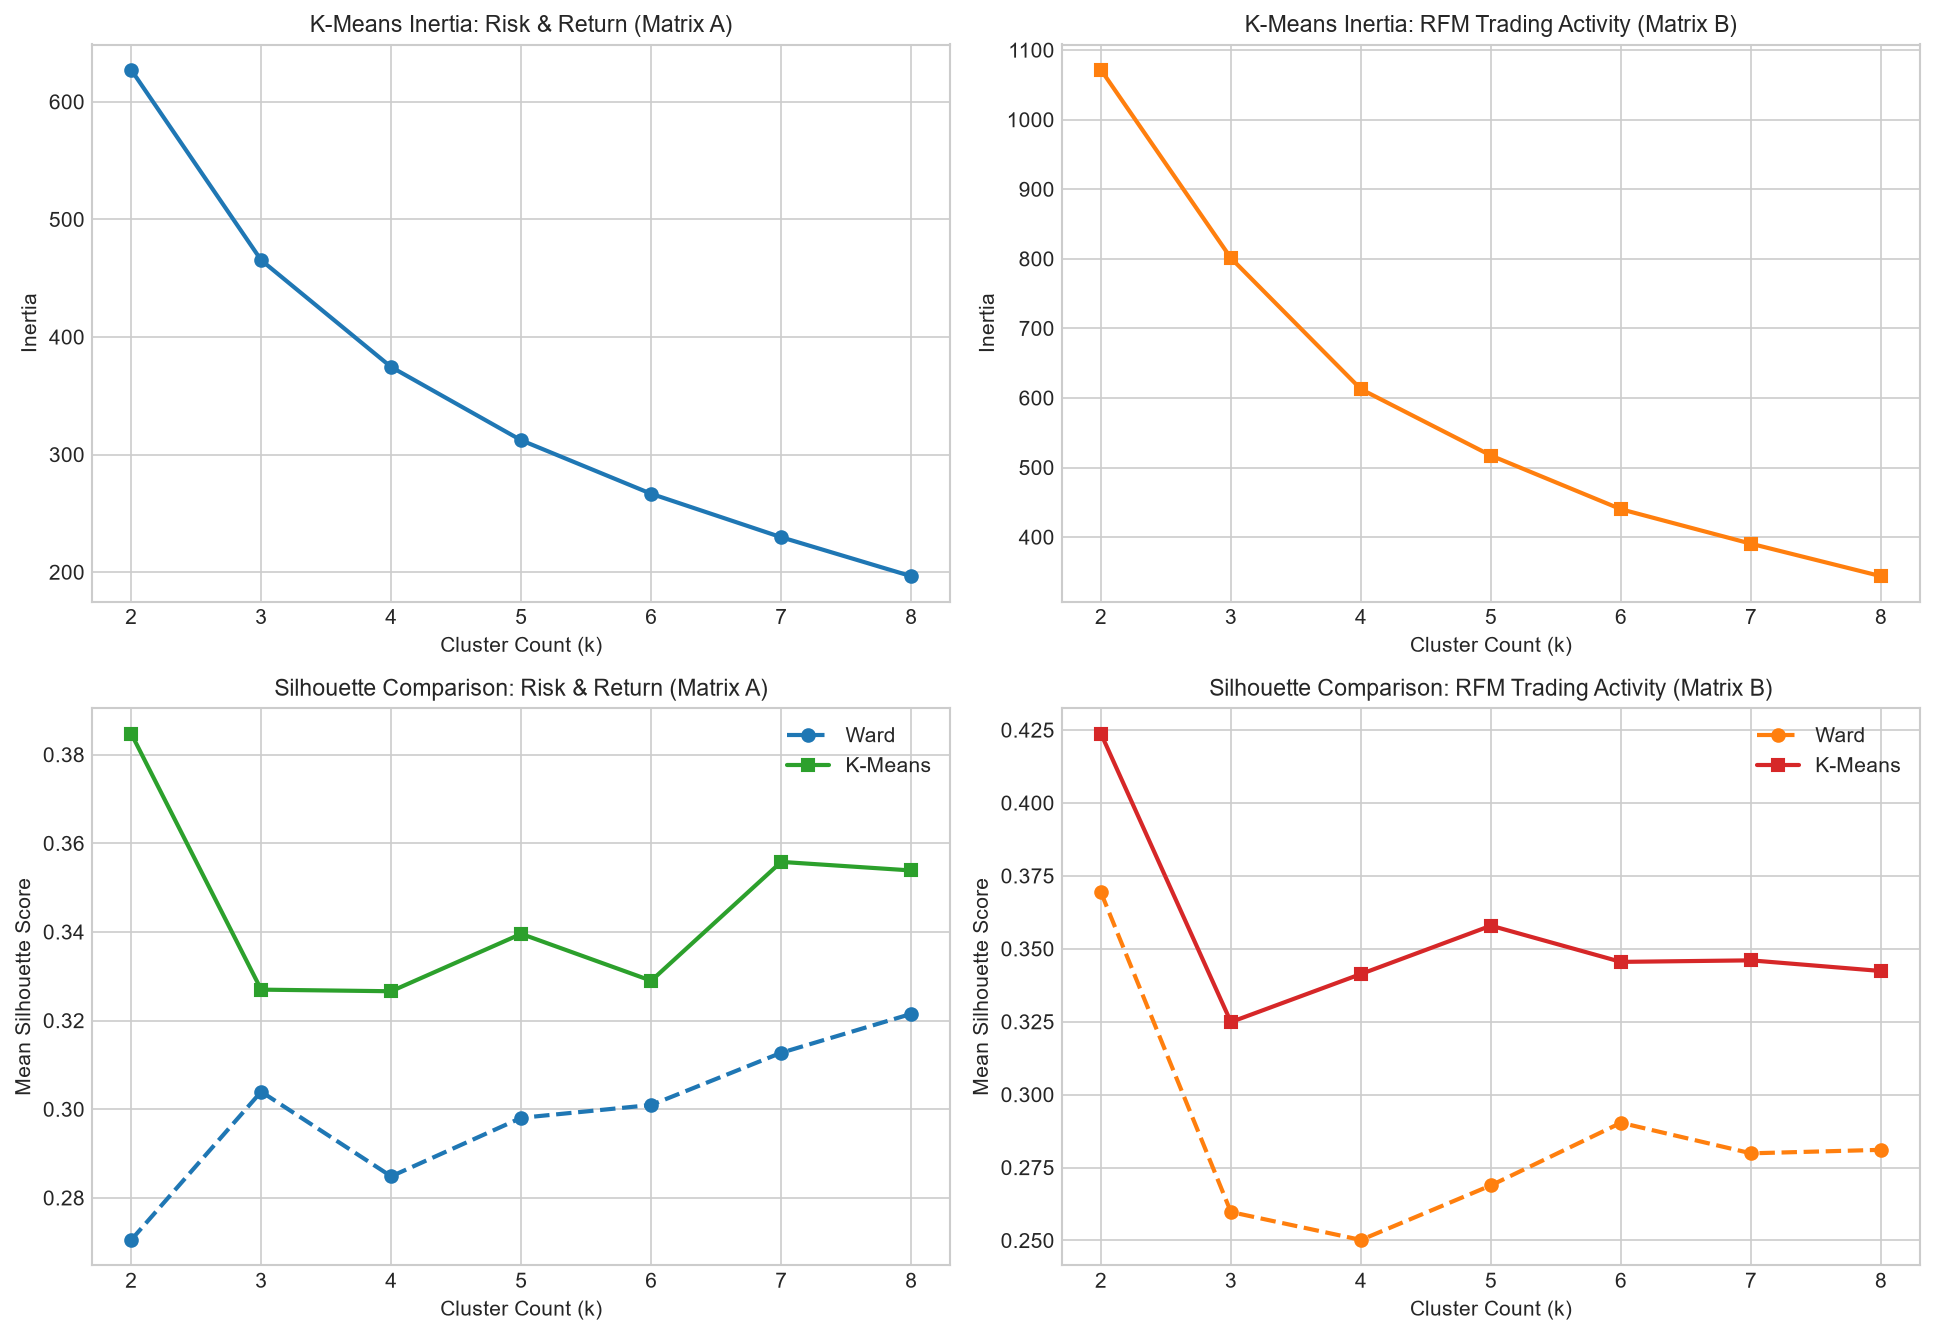

In [11]:
kmeans_records = []
for k in K_RANGE:
    km_a = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=K_MEANS_N_INIT)
    la = km_a.fit_predict(matrix_a_scaled.values)
    sa = pd.Series(la).value_counts()

    km_b = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=K_MEANS_N_INIT)
    lb = km_b.fit_predict(matrix_b_scaled.values)
    sb = pd.Series(lb).value_counts()

    kmeans_records.append({
        "k": k,
        "matrix_a_inertia": km_a.inertia_,
        "matrix_a_silhouette": silhouette_score(matrix_a_scaled.values, la),
        "matrix_a_min_size": int(sa.min()),
        "matrix_a_max_size": int(sa.max()),
        "matrix_b_inertia": km_b.inertia_,
        "matrix_b_silhouette": silhouette_score(matrix_b_scaled.values, lb),
        "matrix_b_min_size": int(sb.min()),
        "matrix_b_max_size": int(sb.max()),
    })
kmeans_diag_df = pd.DataFrame(kmeans_records)
display(kmeans_diag_df.round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].plot(kmeans_diag_df["k"], kmeans_diag_df["matrix_a_inertia"], "o-", color="#1f77b4", lw=2)
axes[0, 0].set_title("K-Means Inertia: Risk & Return (Matrix A)")
axes[0, 0].set_xlabel("Cluster Count (k)")
axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(kmeans_diag_df["k"], kmeans_diag_df["matrix_b_inertia"], "s-", color="#ff7f0e", lw=2)
axes[0, 1].set_title("K-Means Inertia: RFM Trading Activity (Matrix B)")
axes[0, 1].set_xlabel("Cluster Count (k)")
axes[0, 1].set_ylabel("Inertia")

axes[1, 0].plot(ward_diag_df["k"], ward_diag_df["matrix_a_silhouette"], "o--", label="Ward", color="#1f77b4", lw=2)
axes[1, 0].plot(kmeans_diag_df["k"], kmeans_diag_df["matrix_a_silhouette"], "s-", label="K-Means", color="#2ca02c", lw=2)
axes[1, 0].set_title("Silhouette Comparison: Risk & Return (Matrix A)")
axes[1, 0].set_xlabel("Cluster Count (k)")
axes[1, 0].set_ylabel("Mean Silhouette Score")
axes[1, 0].legend()

axes[1, 1].plot(ward_diag_df["k"], ward_diag_df["matrix_b_silhouette"], "o--", label="Ward", color="#ff7f0e", lw=2)
axes[1, 1].plot(kmeans_diag_df["k"], kmeans_diag_df["matrix_b_silhouette"], "s-", label="K-Means", color="#d62728", lw=2)
axes[1, 1].set_title("Silhouette Comparison: RFM Trading Activity (Matrix B)")
axes[1, 1].set_xlabel("Cluster Count (k)")
axes[1, 1].set_ylabel("Mean Silhouette Score")
axes[1, 1].legend()

plt.tight_layout()
plt.savefig(FIG_EXPORT_DIR / "fig_2_3_kmeans_elbow_silhouette.png")
plt.show()

## Task 2.4 Cluster profiles and algorithm comparison
Fit all four baseline clustering solutions (`k = 3`) on the identical 488 shares, present original-unit profiles, compare Ward vs. K-Means via Adjusted Rand Index (ARI), and visualize Risk & Return directly plus RFM in 2D PCA space.

,model,cluster,count,share_pct,mean_ret_pct_wk,mean_beta,mean_R_days,mean_F_days,mean_M_B_usd
0,Ward_Return_Beta,1,166,34.016,0.233,0.564,21.283,2.928,24.619
1,Ward_Return_Beta,2,100,20.492,0.618,1.242,20.980,3.130,70.983
2,Ward_Return_Beta,3,222,45.492,0.165,1.156,19.455,2.968,36.025
3,KMeans_Return_Beta,0,164,33.607,0.088,1.135,18.671,3.000,24.652
4,KMeans_Return_Beta,1,203,41.598,0.256,0.632,19.936,2.906,23.414
5,KMeans_Return_Beta,2,121,24.795,0.583,1.323,23.479,3.107,85.840
6,Ward_RFM,1,86,17.623,0.302,1.036,57.000,1.977,48.248
7,Ward_RFM,2,180,36.885,0.327,1.005,12.139,2.939,69.936
8,Ward_RFM,3,222,45.492,0.235,0.921,12.896,3.419,11.013
9,KMeans_RFM,0,151,30.943,0.332,1.050,14.252,2.894,82.119


ARI Ward vs K-Means (Risk/Return): 0.5908
ARI Ward vs K-Means (RFM)        : 0.6373
Cross-Domain ARI (Ward | K-Means): 0.0076 | 0.0179
RFM PCA Explained Variance       : PC1=45.79%, PC2=33.65%, Total=79.44%


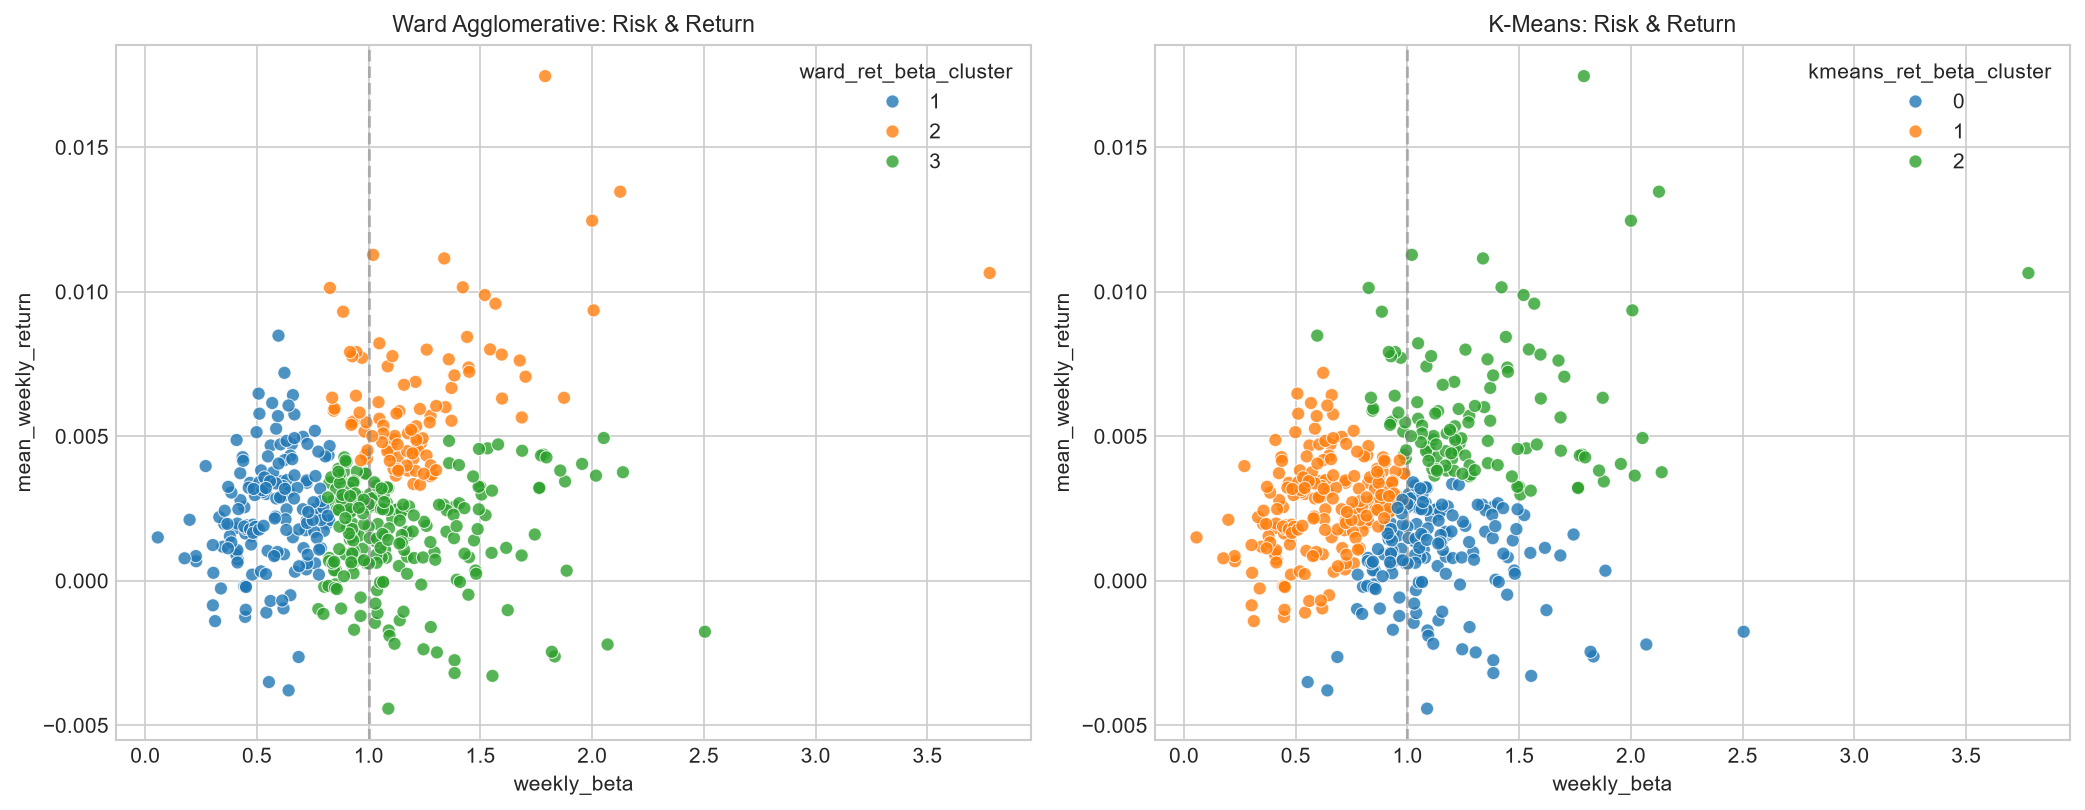

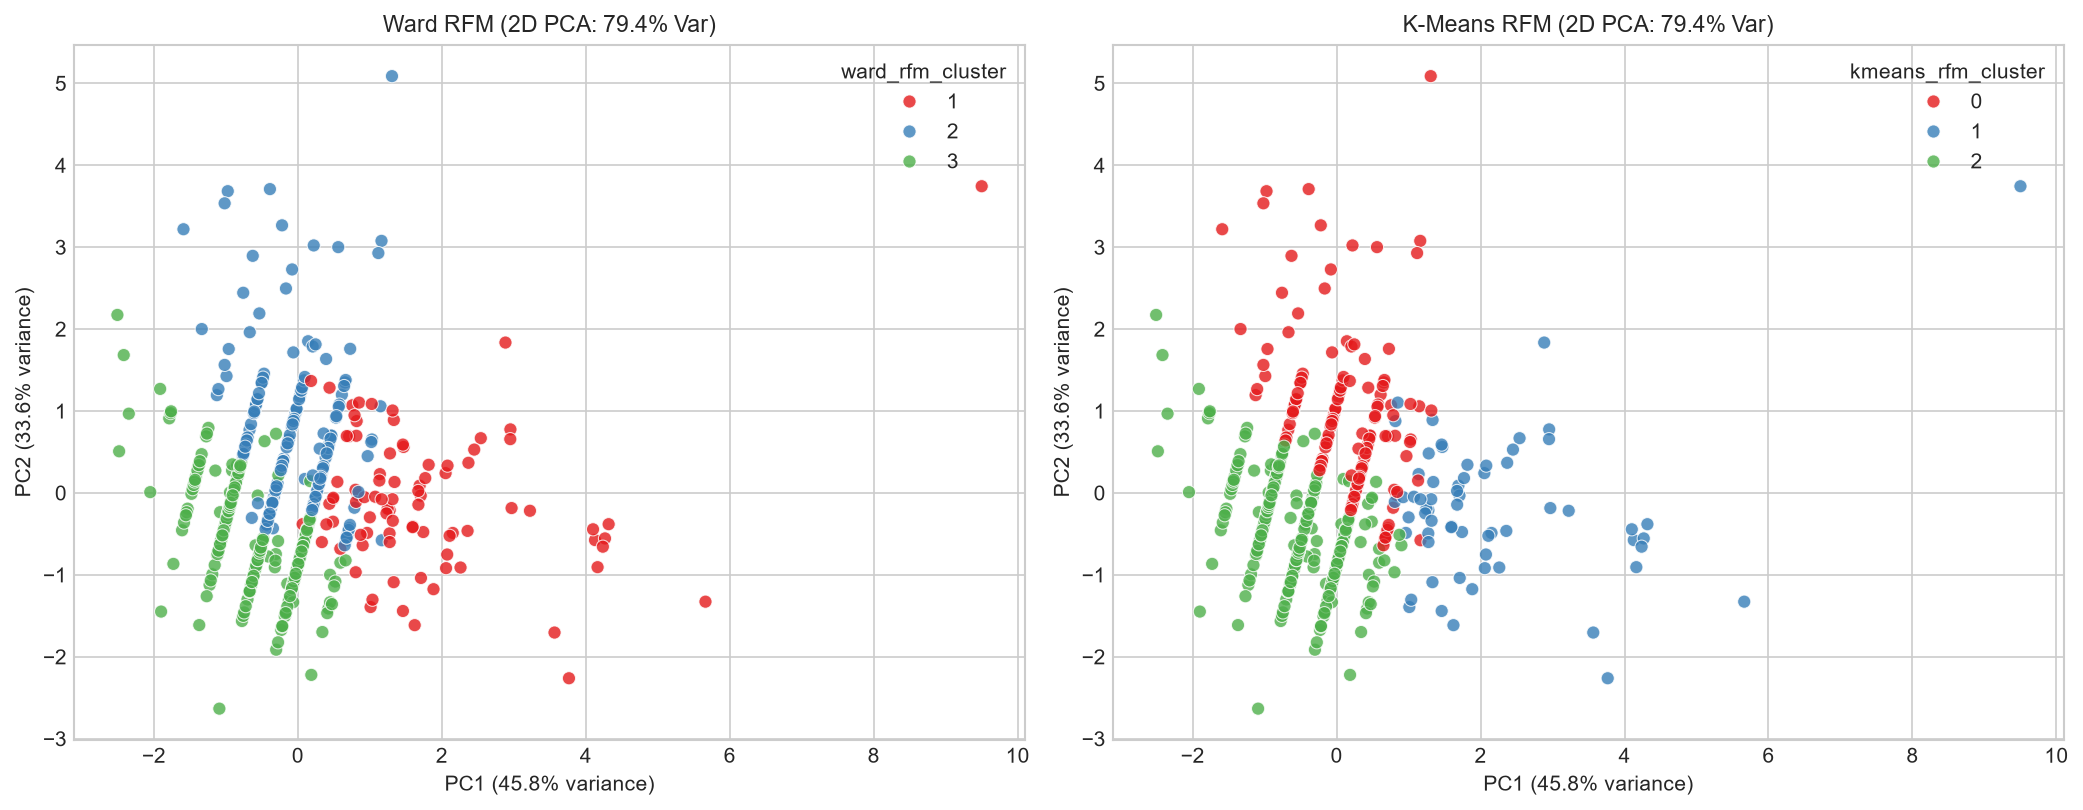

In [12]:
K_RET_BETA = 3
K_RFM = 3

ward_a_labels = fcluster(linkage_a, t=K_RET_BETA, criterion="maxclust")
km_a_labels = KMeans(n_clusters=K_RET_BETA, random_state=RANDOM_STATE, n_init=K_MEANS_N_INIT).fit_predict(matrix_a_scaled.values)
ward_b_labels = fcluster(linkage_b, t=K_RFM, criterion="maxclust")
km_b_labels = KMeans(n_clusters=K_RFM, random_state=RANDOM_STATE, n_init=K_MEANS_N_INIT).fit_predict(matrix_b_scaled.values)

meta_dict = constituents_df.set_index("ticker").to_dict(orient="index")
assignments_df = pd.DataFrame(index=common_tickers)
assignments_df["company_name"] = [meta_dict.get(t, {}).get("company_name", t) for t in common_tickers]
assignments_df["sector"] = [meta_dict.get(t, {}).get("sector", "Unknown") for t in common_tickers]
assignments_df["mean_weekly_return"] = matrix_a_raw["mean_weekly_return"]
assignments_df["weekly_beta"] = matrix_a_raw["weekly_beta"]
assignments_df["R"] = matrix_b_raw["R"]
assignments_df["F"] = matrix_b_raw["F"]
assignments_df["M"] = original_m
assignments_df["log1p_M"] = matrix_b_raw["log1p_M"]
assignments_df["ward_ret_beta_cluster"] = ward_a_labels
assignments_df["kmeans_ret_beta_cluster"] = km_a_labels
assignments_df["ward_rfm_cluster"] = ward_b_labels
assignments_df["kmeans_rfm_cluster"] = km_b_labels

pca_rfm = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca_rfm.fit_transform(matrix_b_scaled.values)
assignments_df["rfm_pca_1"] = pca_coords[:, 0]
assignments_df["rfm_pca_2"] = pca_coords[:, 1]

profile_rows = []
for model_name, col in [
    ("Ward_Return_Beta", "ward_ret_beta_cluster"),
    ("KMeans_Return_Beta", "kmeans_ret_beta_cluster"),
    ("Ward_RFM", "ward_rfm_cluster"),
    ("KMeans_RFM", "kmeans_rfm_cluster"),
]:
    for c, sub in assignments_df.groupby(col):
        profile_rows.append({
            "model": model_name,
            "cluster": c,
            "count": len(sub),
            "share_pct": (len(sub) / len(assignments_df)) * 100,
            "mean_ret_pct_wk": sub["mean_weekly_return"].mean() * 100,
            "mean_beta": sub["weekly_beta"].mean(),
            "mean_R_days": sub["R"].mean(),
            "mean_F_days": sub["F"].mean(),
            "mean_M_B_usd": (sub["M"] / 1e9).mean(),
        })
profiles_df = pd.DataFrame(profile_rows)
display(profiles_df.round(3))

ari_rb = adjusted_rand_score(ward_a_labels, km_a_labels)
ari_rfm = adjusted_rand_score(ward_b_labels, km_b_labels)
ari_cross_w = adjusted_rand_score(ward_a_labels, ward_b_labels)
ari_cross_k = adjusted_rand_score(km_a_labels, km_b_labels)
print(f"ARI Ward vs K-Means (Risk/Return): {ari_rb:.4f}")
print(f"ARI Ward vs K-Means (RFM)        : {ari_rfm:.4f}")
print(f"Cross-Domain ARI (Ward | K-Means): {ari_cross_w:.4f} | {ari_cross_k:.4f}")
print(f"RFM PCA Explained Variance       : PC1={pca_rfm.explained_variance_ratio_[0]:.2%}, PC2={pca_rfm.explained_variance_ratio_[1]:.2%}, Total={pca_rfm.explained_variance_ratio_.sum():.2%}")

# Scatter: Risk & Return
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=assignments_df, x="weekly_beta", y="mean_weekly_return", hue="ward_ret_beta_cluster", palette="tab10", alpha=0.8, s=40, ax=axes[0])
axes[0].set_title("Ward Agglomerative: Risk & Return")
axes[0].axvline(1.0, color="gray", linestyle="--", alpha=0.5)
sns.scatterplot(data=assignments_df, x="weekly_beta", y="mean_weekly_return", hue="kmeans_ret_beta_cluster", palette="tab10", alpha=0.8, s=40, ax=axes[1])
axes[1].set_title("K-Means: Risk & Return")
axes[1].axvline(1.0, color="gray", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(FIG_EXPORT_DIR / "fig_2_4_clusters_risk_return.png")
plt.show()

# Scatter: RFM 2D PCA
pc1_v, pc2_v = pca_rfm.explained_variance_ratio_ * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=assignments_df, x="rfm_pca_1", y="rfm_pca_2", hue="ward_rfm_cluster", palette="Set1", alpha=0.8, s=40, ax=axes[0])
axes[0].set_title(f"Ward RFM (2D PCA: {pc1_v+pc2_v:.1f}% Var)")
axes[0].set_xlabel(f"PC1 ({pc1_v:.1f}% variance)")
axes[0].set_ylabel(f"PC2 ({pc2_v:.1f}% variance)")
sns.scatterplot(data=assignments_df, x="rfm_pca_1", y="rfm_pca_2", hue="kmeans_rfm_cluster", palette="Set1", alpha=0.8, s=40, ax=axes[1])
axes[1].set_title(f"K-Means RFM (2D PCA: {pc1_v+pc2_v:.1f}% Var)")
axes[1].set_xlabel(f"PC1 ({pc1_v:.1f}% variance)")
axes[1].set_ylabel(f"PC2 ({pc2_v:.1f}% variance)")
plt.tight_layout()
plt.savefig(FIG_EXPORT_DIR / "fig_2_4_clusters_rfm_pca.png")
plt.show()

## Task 2.5 RFM sensitivity and correlated inputs
### Task 2.5.1 Correlation analysis
Calculate Pearson and Spearman correlations among `R`, `F`, and `log1p(M)`. Correlated variables share variance along a common axis, which can amplify their combined contribution to Euclidean distance even after standardization.

,Pair,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,R vs F,-0.34613,0.00000,-0.19771,0.00001
1,R vs log1p_M,0.15265,0.00072,0.13770,0.00230
2,F vs log1p_M,0.01286,0.77697,-0.04831,0.28681


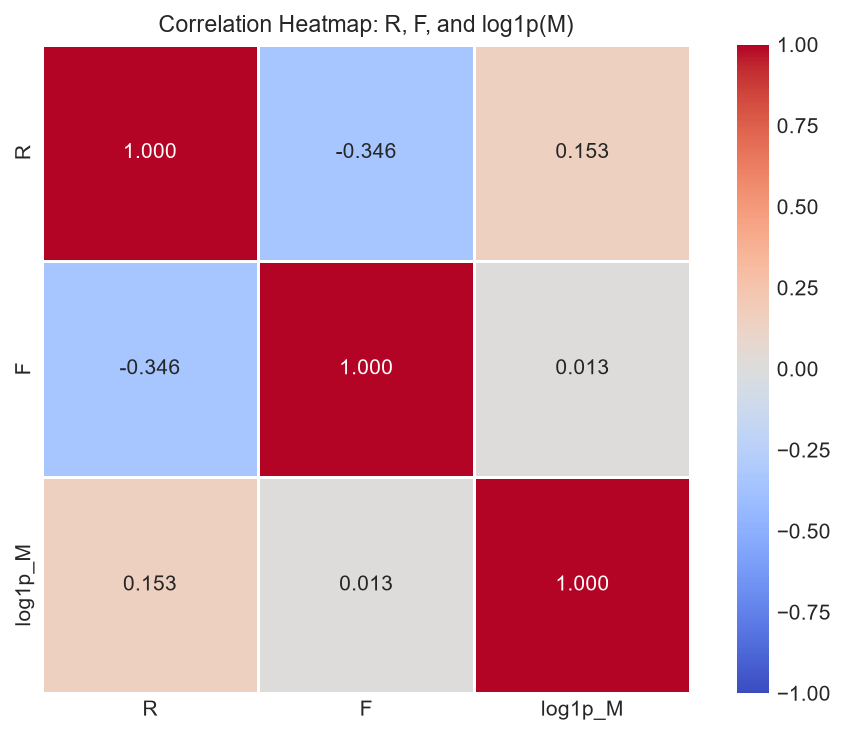

In [13]:
pearson_corr = matrix_b_raw[["R", "F", "log1p_M"]].corr(method="pearson")
corr_rows = []
for v1, v2 in [("R", "F"), ("R", "log1p_M"), ("F", "log1p_M")]:
    pr, pp = pearsonr(matrix_b_raw[v1], matrix_b_raw[v2])
    sr, sp = spearmanr(matrix_b_raw[v1], matrix_b_raw[v2])
    corr_rows.append({"Pair": f"{v1} vs {v2}", "Pearson_r": pr, "Pearson_p": pp, "Spearman_rho": sr, "Spearman_p": sp})
display(pd.DataFrame(corr_rows).round(5))

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f", square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap: R, F, and log1p(M)")
plt.tight_layout()
plt.savefig(FIG_EXPORT_DIR / "fig_2_5_correlation_heatmap.png")
plt.show()

### Task 2.5.2 Removal of Monetary
Refit `StandardScaler` on `[R, F]` alone across the same 488 shares and refit Ward hierarchical clustering at `k = 3`. Compare cluster membership agreement with the Adjusted Rand Index (ARI) and inspect traded value (`M`) profiles.

Adjusted Rand Index (Full RFM vs Reduced RF): 0.2678


,cluster,count,mean_M_B,median_M_B,model
0,1,86,48.25,21.45,"Full RFM (R, F, log1p_M)"
1,2,180,69.94,34.25,"Full RFM (R, F, log1p_M)"
2,3,222,11.01,10.14,"Full RFM (R, F, log1p_M)"
0,1,90,46.22,20.49,"Reduced RF (R, F only)"
1,2,125,34.34,17.70,"Reduced RF (R, F only)"
2,3,273,39.31,14.78,"Reduced RF (R, F only)"


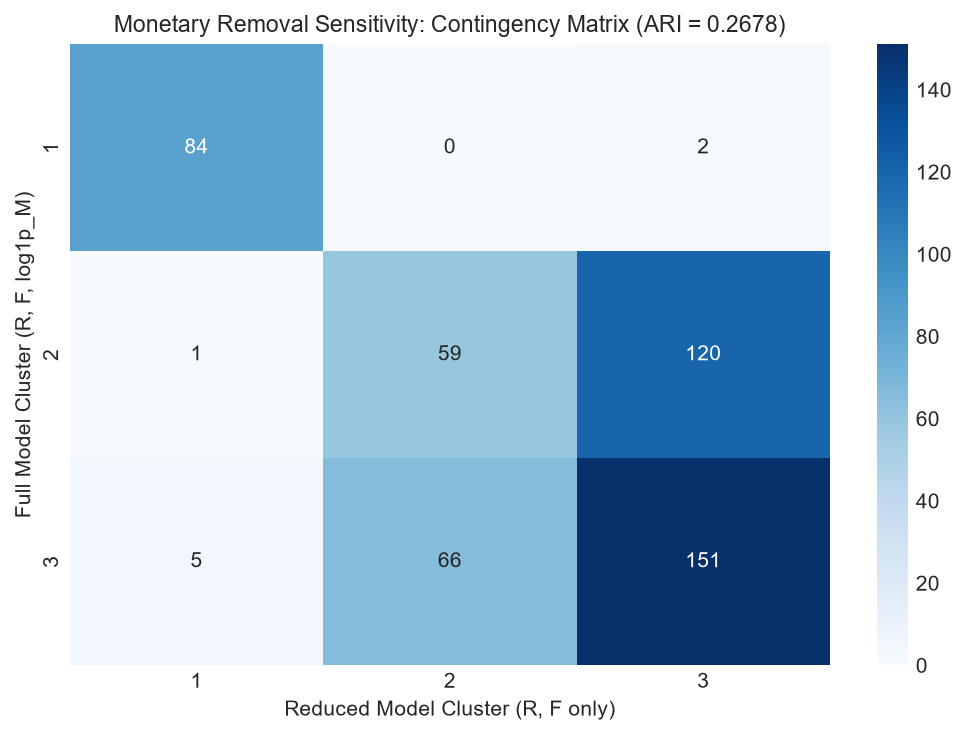

In [14]:
rf_scaled = StandardScaler().fit_transform(matrix_b_raw[["R", "F"]])
rf_labels = fcluster(linkage(rf_scaled, method="ward", metric="euclidean"), t=K_RFM, criterion="maxclust")
ari_m_removal = adjusted_rand_score(assignments_df["ward_rfm_cluster"], rf_labels)

sens_df = pd.DataFrame({
    "full_rfm_cluster": assignments_df["ward_rfm_cluster"],
    "reduced_rf_cluster": rf_labels,
    "M": original_m,
}, index=common_tickers)

print(f"Adjusted Rand Index (Full RFM vs Reduced RF): {ari_m_removal:.4f}")
full_prof = sens_df.groupby("full_rfm_cluster")["M"].agg(count="count", mean_M_B=lambda s: s.mean()/1e9, median_M_B=lambda s: s.median()/1e9)
full_prof["model"] = "Full RFM (R, F, log1p_M)"
red_prof = sens_df.groupby("reduced_rf_cluster")["M"].agg(count="count", mean_M_B=lambda s: s.mean()/1e9, median_M_B=lambda s: s.median()/1e9)
red_prof["model"] = "Reduced RF (R, F only)"
display(pd.concat([full_prof.reset_index().rename(columns={"full_rfm_cluster": "cluster"}),
                   red_prof.reset_index().rename(columns={"reduced_rf_cluster": "cluster"})]).round(2))

ct_sens = pd.crosstab(sens_df["full_rfm_cluster"], sens_df["reduced_rf_cluster"])
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(ct_sens, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title(f"Monetary Removal Sensitivity: Contingency Matrix (ARI = {ari_m_removal:.4f})")
ax.set_xlabel("Reduced Model Cluster (R, F only)")
ax.set_ylabel("Full Model Cluster (R, F, log1p_M)")
plt.tight_layout()
plt.savefig(FIG_EXPORT_DIR / "fig_2_5_sensitivity_comparison.png")
plt.show()

# Task 3 Business Intelligence and Critical Review
Supporting sector composition analysis and Chi-square association tests comparing Risk & Return clusters against RFM clusters.

Chi-Square Sector Association -> Risk/Return: chi2=164.91, p=8.41e-25 | RFM: chi2=53.90, p=5.99e-05


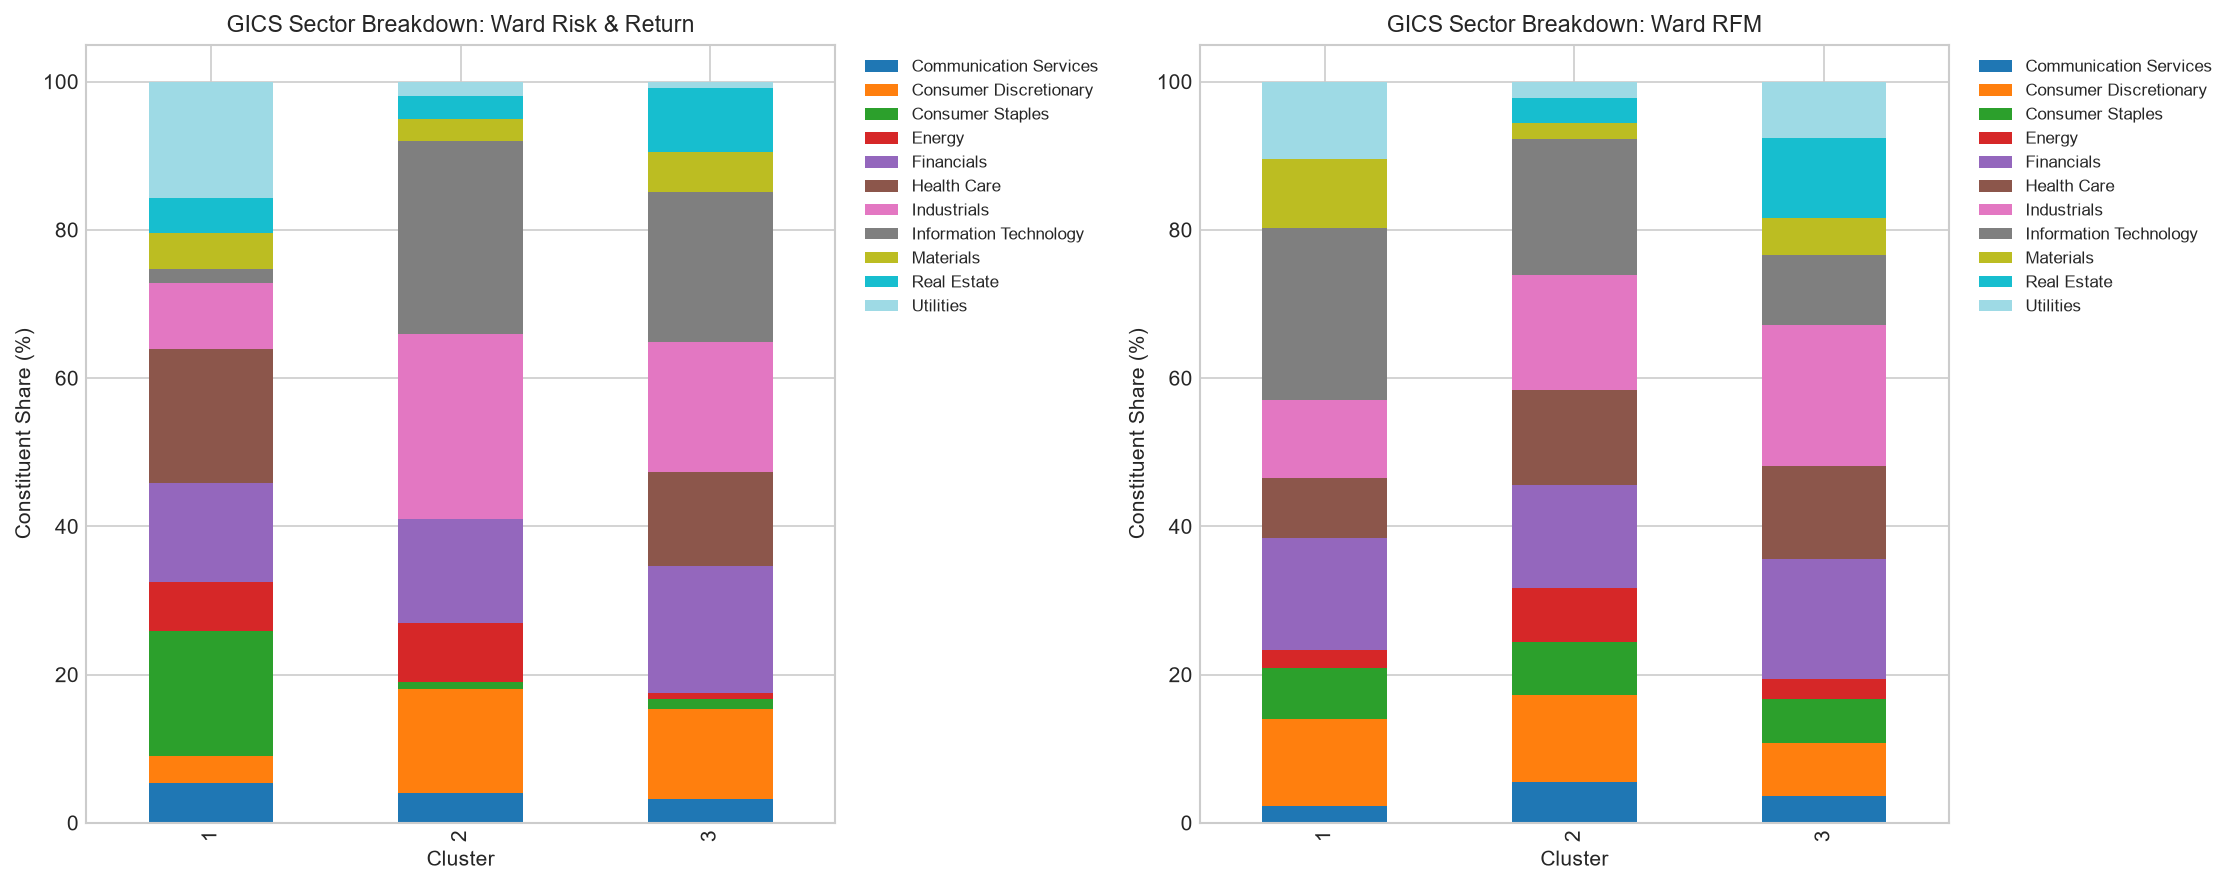

In [15]:
# GICS Sector Composition across Ward Risk/Return and Ward RFM
ct_ret = pd.crosstab(assignments_df["ward_ret_beta_cluster"], assignments_df["sector"], normalize="index") * 100
ct_rfm = pd.crosstab(assignments_df["ward_rfm_cluster"], assignments_df["sector"], normalize="index") * 100

chi_ret, p_ret, _, _ = chi2_contingency(pd.crosstab(assignments_df["ward_ret_beta_cluster"], assignments_df["sector"]))
chi_rfm, p_rfm, _, _ = chi2_contingency(pd.crosstab(assignments_df["ward_rfm_cluster"], assignments_df["sector"]))
print(f"Chi-Square Sector Association -> Risk/Return: chi2={chi_ret:.2f}, p={p_ret:.2e} | RFM: chi2={chi_rfm:.2f}, p={p_rfm:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ct_ret.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20")
axes[0].set_title("GICS Sector Breakdown: Ward Risk & Return")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Constituent Share (%)")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

ct_rfm.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab20")
axes[1].set_title("GICS Sector Breakdown: Ward RFM")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Constituent Share (%)")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_EXPORT_DIR / "fig_2_4_sector_composition.png")
plt.show()